Un magazin este vizitat de $n$ clienţi într-o anumită zi. Numărul $Y$ de clienţi care cumpără un anumit produs
e distribuit $Binomial(n, \theta)$, unde $\theta$ este probabilitatea ca un client să cumpere acel produs. Să presupunem că
îl cunoaştem pe $\theta$ şi că distribuţia a priori pentru $n$ este Poisson(10).
1. Folosiţi PyMC pentru a calcula distribuţia a posteriori pentru $n$ pentru toate combinaţiile de $Y \in

\{0, 5, 10\} şi \theta \in \{0.2, 0.5\}$. Folosiţi az.plot_posterior pentru a vizualiza toate rezultatele (ideal, într-
o singură fereastră).

2. Explicaţi efectul lui $Y$ şi $\theta$ asupra distribuţiei a posteriori. Puteţi realiza acest lucru într-un fişier
README.md pe care să-l includeţi în repozitorul GitHub.

Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [n]
>Metropolis: [y]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [n]
>Metropolis: [y]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [n]
>Metropolis: [y]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [n]
>Metropolis: [y]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Multiprocess sampling (4 chains in 4 jobs)
CompoundStep
>Metropolis: [n]
>Metropolis: [y]
Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 1 seconds.
Multiprocess sampling (4 chains in 

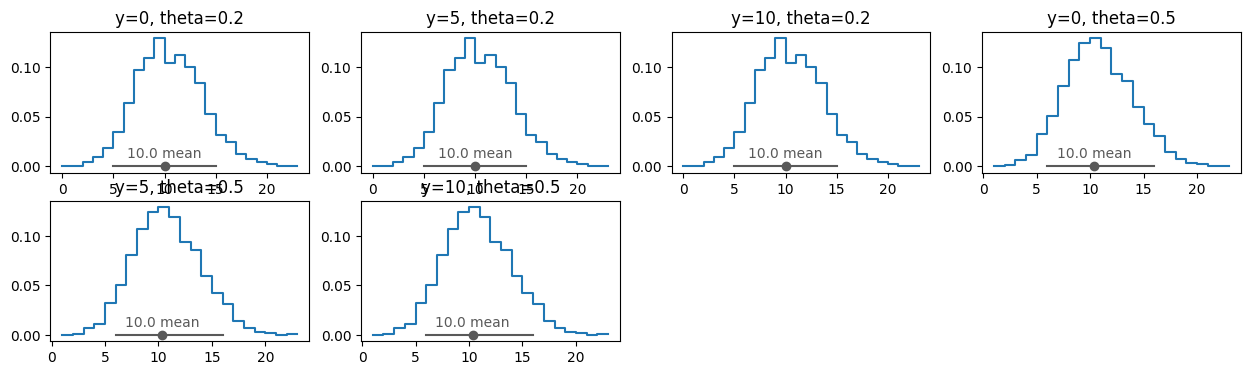

In [ ]:
import numpy as np
import pymc as pm

import arviz as az
import matplotlib.pyplot as plt

post = {}
for theta in (0.2, 0.5):
    for y in (0, 5, 10):
        with pm.Model() as model:
            n = pm.Poisson("n",10)
            pm.Binomial(f"y",n=n,p=theta, observed=y)
            idata = pm.sample(draws = 2000, tune = 2000, random_seed = 67, progressbar=False)
            post[f"y={y}, theta={theta}"] = idata.posterior["n"].values


az.plot_dist(az.from_dict({"posterior": post}),group="posterior", kind="hist", visuals={"remove_axis": False})


$$\begin{align*}
(n | y, \theta) \propto P(y|n) \cdot P(n) & = \frac{n!}{y!(n-y)!} \cdot \theta^y \cdot (1-\theta)^{n-y} \cdot \frac{\lambda^n e^{-\lambda}}{n!} \\
& = \frac{\lambda^y \cdot \theta^y}{y!} \cdot \frac{(1-\theta)^{n-y} \cdot \lambda^{n-y} \cdot e^{-\lambda}}{(n-y)!} \\
& = \frac{\lambda^y \cdot \theta^y}{e^{\lambda\theta} \cdot y!} \cdot \frac{(\lambda (1-\theta))^{n-y} \cdot e^{-\lambda (1-\theta)}}{(n-y)!} \\
& \propto Poisson(n-y, (1-\theta) \lambda) \\
& = Poisson((1-\theta) \lambda) + y
\end{align*}
$$

Prin urmare, $y$ doar va shifta distribuția lui $n$, iar $1-\theta$ este direct proportional cu stdev-ul și media distributiei lui $n$.